# КТ 1 — EDA сырого корпуса

Корпус собран скриптом `scripts/build_corpus.py` (описание источников и решений — в `README.md`).
Здесь он анализируется **до какой-либо чистки**: HTML-разметка, эмодзи, ссылки и дубликаты на месте.

Вопросы, на которые отвечает EDA:
1. Какой типичный размер документа и насколько он варьируется?
2. Что составляет основной шум в данных?
3. Какие тематические кластеры есть в корпусе?
4. Какие проблемы это создаст для чанкинга и ретрива?

In [1]:
import hashlib
import json
import re
from collections import Counter
from pathlib import Path

import emoji
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from datasketch import MinHash, MinHashLSH

pd.set_option("display.max_colwidth", 120)
plt.rcParams["figure.dpi"] = 110

ROOT = Path.cwd()
DATA = ROOT / "data"
CACHE = DATA / "cache"
CACHE.mkdir(exist_ok=True)

df = pd.DataFrame([json.loads(l) for l in open(DATA / "corpus.jsonl", encoding="utf-8")])
df["date"] = pd.to_datetime(df["date"])
TAG_RE = re.compile(r"<[^>]+>")
df["visible"] = df["text"].map(lambda t: re.sub(r"\s+", " ", TAG_RE.sub(" ", t)).strip())
print(len(df), "документов")

20990 документов


## 1. Состав корпуса

In [2]:
by_src = df.groupby("source").agg(docs=("doc_id", "size"), first=("date", "min"), last=("date", "max"))
by_src["share_%"] = (by_src["docs"] / len(df) * 100).round(1)
by_src

,docs,first,last,share_%
source,,,,
dota2ru_article,36,2023-08-09,2026-09-15,0.2
dota2ru_comment,2692,2023-08-08,2026-09-30,12.8
patchnotes,3447,2023-08-08,2026-09-15,16.4
tg_Dota2,6964,2023-08-08,2026-10-24,33.2
tg_gabenews,7851,2023-08-30,2026-10-24,37.4


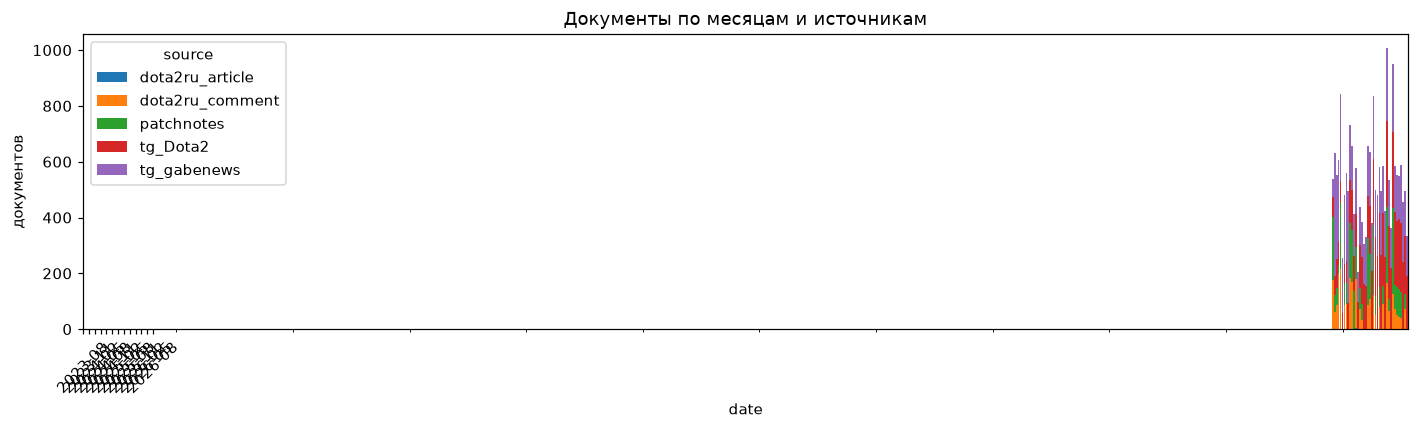

In [3]:
monthly = df.groupby([df["date"].dt.to_period("M"), "source"]).size().unstack(fill_value=0)
ax = monthly.plot(kind="bar", stacked=True, figsize=(13, 4), width=0.9)
ax.set_xticks(range(0, len(monthly), 3))
ax.set_xticklabels([str(p) for p in monthly.index[::3]], rotation=45)
ax.set_title("Документы по месяцам и источникам")
ax.set_ylabel("документов")
plt.tight_layout()

## 2. Длины документов

Токены считаются токенизатором **BGE-M3** (XLM-RoBERTa, SentencePiece) — это одна из моделей,
которыми корпус будет индексироваться дальше, так что длины близки к реальным.
Считаем два варианта: сырой текст (как его увидел бы наивный пайплайн, с HTML) и видимый текст без тегов.

In [4]:
from transformers import AutoTokenizer

tok = AutoTokenizer.from_pretrained("BAAI/bge-m3")
len_cache = CACHE / "token_lens.parquet"
if len_cache.exists():
    lens = pd.read_parquet(len_cache)
else:
    def count(texts):
        return [len(x) for x in tok(list(texts), add_special_tokens=False)["input_ids"]]
    lens = pd.DataFrame({"doc_id": df["doc_id"], "tok_raw": count(df["text"]), "tok_visible": count(df["visible"])})
    lens.to_parquet(len_cache)
df = df.merge(lens, on="doc_id")
print("токенов всего: сырых", df["tok_raw"].sum(), "| видимых", df["tok_visible"].sum())

[transformers] Token indices sequence length is longer than the specified maximum sequence length for this model (97207 > 8192). Running this sequence through the model will result in indexing errors


токенов всего: сырых 10611868 | видимых 2094307


In [5]:
def length_stats(col):
    g = df.groupby("source")[col]
    s = g.describe(percentiles=[0.1, 0.5, 0.9])[["count", "mean", "std", "min", "10%", "50%", "90%", "max"]]
    s["<50_%"] = g.apply(lambda x: (x < 50).mean() * 100)
    s[">2000_%"] = g.apply(lambda x: (x > 2000).mean() * 100)
    s.loc["ВСЕГО"] = [*df[col].describe(percentiles=[0.1, 0.5, 0.9])[["count", "mean", "std", "min", "10%", "50%", "90%", "max"]],
                     (df[col] < 50).mean() * 100, (df[col] > 2000).mean() * 100]
    return s.round(1)

print("Видимый текст:")
display(length_stats("tok_visible"))
print("Сырой текст с разметкой:")
display(length_stats("tok_raw"))

Видимый текст:


,count,mean,std,min,10%,50%,90%,max,<50_%,>2000_%
source,,,,,,,,,,
dota2ru_article,36.0,10339.3,14138.5,1591.0,2434.0,4145.5,25528.0,54945.0,0.0,97.2
dota2ru_comment,2692.0,30.5,33.6,0.0,6.0,21.0,64.0,502.0,83.9,0.0
patchnotes,3447.0,94.0,130.7,10.0,24.0,54.0,203.4,2226.0,45.8,0.1
tg_Dota2,6964.0,74.5,56.3,0.0,34.0,57.0,135.0,956.0,36.9,0.0
tg_gabenews,7851.0,101.6,76.8,0.0,35.0,79.0,193.0,870.0,26.3,0.0
ВСЕГО,20990.0,99.8,721.3,0.0,24.0,58.0,167.0,54945.0,40.4,0.2


Сырой текст с разметкой:


,count,mean,std,min,10%,50%,90%,max,<50_%,>2000_%
source,,,,,,,,,,
dota2ru_article,36.0,51336.7,57152.7,13491.0,15639.5,26752.0,115746.0,233904.0,0.0,100.0
dota2ru_comment,2692.0,74.1,57.0,21.0,35.0,55.0,124.0,801.0,41.5,0.0
patchnotes,3447.0,94.5,132.9,10.0,24.0,54.0,204.0,2226.0,45.6,0.1
tg_Dota2,6964.0,429.7,606.5,33.0,181.0,248.0,767.0,6815.0,0.0,2.8
tg_gabenews,7851.0,668.2,472.4,33.0,295.0,511.0,1220.0,6974.0,0.1,1.7
ВСЕГО,20990.0,505.6,3186.0,10.0,42.0,282.0,928.0,233904.0,12.8,1.8


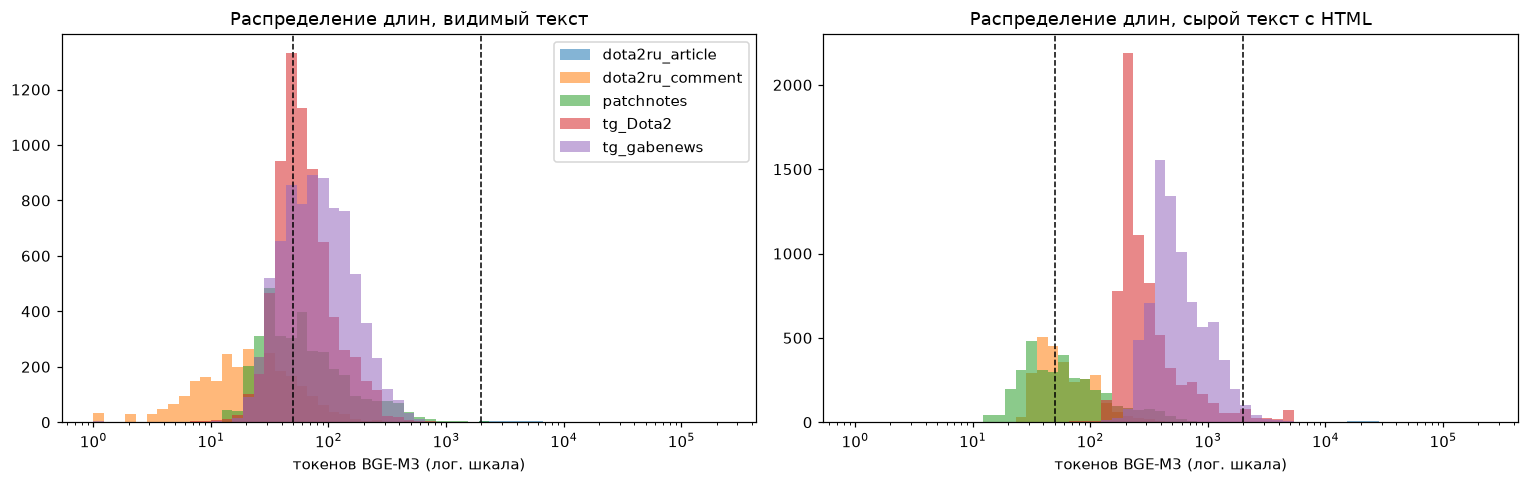

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
bins = np.logspace(0, np.log10(df["tok_raw"].max() + 1), 60)
for ax, col, title in zip(axes, ["tok_visible", "tok_raw"], ["видимый текст", "сырой текст с HTML"]):
    for src, g in df.groupby("source"):
        ax.hist(g[col].clip(lower=1), bins=bins, alpha=0.55, label=src)
    ax.set_xscale("log")
    ax.axvline(50, color="k", ls="--", lw=1)
    ax.axvline(2000, color="k", ls="--", lw=1)
    ax.set_title(f"Распределение длин, {title}")
    ax.set_xlabel("токенов BGE-M3 (лог. шкала)")
axes[0].legend()
plt.tight_layout()

Примеры выбросов: самые короткие и самые длинные документы.

In [7]:
cols = ["source", "tok_visible", "visible"]
display(df[df["tok_visible"] < 5].sample(8, random_state=1)[cols])
display(df.nlargest(5, "tok_visible")[["source", "tok_visible", "tok_raw", "title"]])

,source,tok_visible,visible
5243,dota2ru_comment,2,гавно
4553,dota2ru_comment,3,что с ним
4333,dota2ru_comment,4,Дежавю.
4723,dota2ru_comment,3,не складывается
5731,dota2ru_comment,1,+1
4709,dota2ru_comment,0,
5722,dota2ru_comment,0,
5799,dota2ru_comment,2,Почему?


,source,tok_visible,tok_raw,title
4359,dota2ru_article,54945,211056,В Dota 2 вышел глобальный патч 7.36. Добавлены две новые механики: врождённые способности и аспекты
5768,dota2ru_article,50064,233904,В Dota 2 вышел патч 7.41 — удалены аспекты
5001,dota2ru_article,49137,186260,В Dota 2 вышел патч 7.38 «Вольные воды»
5536,dota2ru_article,28264,132012,"В Dota 2 вышел патч 7.40 — изменения карты, балансные правки и обновлённый порядок драфта в CM"
5196,dota2ru_article,22792,99480,В Dota 2 вышел патч 7.39 «Весенняя встряска»


## 3. Шум: доля «мусорных» токенов

Сырой текст разбивается регулярным выражением на единицы и каждая относится к классу:
HTML-тег, URL, эмодзи, число, спецсимвол или слово. Доля классов показывает,
насколько агрессивной должна быть предобработка в КТ 2.

URL вынимаются первым проходом — в том числе из атрибутов `href`/`src`, иначе
они растворились бы внутри HTML-тегов; эмодзи — вторым, через библиотеку `emoji`.

In [8]:
URL_RE = re.compile(r"https?://[^\s\"'<>]+|www\.[^\s\"'<>]+|t\.me/[^\s\"'<>]+")
UNIT_RE = re.compile(r"(?P<html><[^>]+>)|(?P<num>\d+(?:[.,]\d+)*%?)|(?P<word>[^\W\d_]+)|(?P<special>[^\w\s])")

def noise_profile(text):
    c = Counter()
    text, c["url"] = URL_RE.subn(" ", text)
    text = emoji.replace_emoji(text, replace=" \x00 ")
    c["emoji"] = text.count("\x00")
    for m in UNIT_RE.finditer(text.replace("\x00", " ")):
        c[m.lastgroup] += 1
    return c

noise = pd.DataFrame([noise_profile(t) for t in df["text"]]).fillna(0)
noise["source"] = df["source"].values
cls = ["word", "html", "url", "emoji", "num", "special"]
share = noise.groupby("source")[cls].sum()
share.loc["ВСЕГО"] = share.sum()
share = (share.div(share.sum(axis=1), axis=0) * 100).round(1)
share["мусор_%"] = (100 - share["word"]).round(1)
share

,word,html,url,emoji,num,special,мусор_%
source,,,,,,,
dota2ru_article,39.8,29.9,0.1,0.0,8.5,21.7,60.2
dota2ru_comment,65.9,18.1,0.1,0.0,2.5,13.4,34.1
patchnotes,59.9,0.2,0.0,0.0,16.2,23.8,40.1
tg_Dota2,37.9,45.7,1.1,3.7,3.0,8.5,62.1
tg_gabenews,36.9,47.0,1.4,4.1,1.8,8.9,63.1
ВСЕГО,40.8,38.2,0.9,2.8,4.7,12.6,59.2


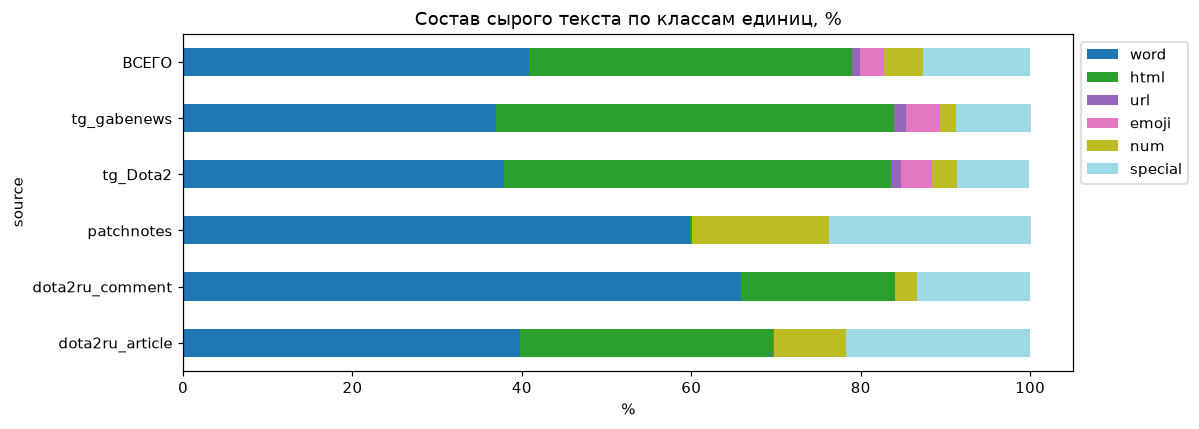

In [9]:
share.drop(columns="мусор_%").plot(kind="barh", stacked=True, figsize=(11, 4), colormap="tab20")
plt.title("Состав сырого текста по классам единиц, %")
plt.xlabel("%")
plt.legend(bbox_to_anchor=(1, 1))
plt.tight_layout()

Дополнительные признаки «грязи» по источникам: доля документов с эмодзи, ссылками, цитатами,
пересылками, медиа без текста, а также рекламные маркеры в Telegram.

In [10]:
# «бонус» сюда не входит: в патчноутах это игровой термин («бонус к урону»)
ADS_RE = re.compile(r"промокод|ставк|казино|букмекер|фрибет|реклама|erid|бездеп", re.I)
flags = pd.DataFrame({
    "source": df["source"],
    "с эмодзи": noise["emoji"] > 0,
    "со ссылкой": noise["url"] > 0,
    "с цитатой": df["meta"].map(lambda m: bool(m.get("has_quote"))),
    "пересылка": df["meta"].map(lambda m: bool(m.get("forwarded_from"))),
    "медиа": df["meta"].map(lambda m: bool(m.get("has_photo") or m.get("has_video"))),
    "реклама/ставки": df["visible"].str.contains(ADS_RE),
    "латиница>50%": df["visible"].map(lambda t: sum(ch.isascii() and ch.isalpha() for ch in t) > 0.5 * max(1, sum(ch.isalpha() for ch in t))),
})
(flags.groupby("source").mean() * 100).round(1)

,с эмодзи,со ссылкой,с цитатой,пересылка,медиа,реклама/ставки,латиница>50%
source,,,,,,,
dota2ru_article,0.0,100.0,0.0,0.0,0.0,0.0,0.0
dota2ru_comment,0.0,0.8,0.0,0.0,0.0,0.1,0.8
patchnotes,0.0,0.0,0.0,0.0,0.0,0.0,1.8
tg_Dota2,99.5,91.9,0.0,2.8,99.0,0.9,1.1
tg_gabenews,99.8,93.7,0.0,0.2,96.1,1.0,3.9


## 4. Дубликаты и near-duplicates

Только фиксируем, ничего не удаляем (удаление — шаг предобработки КТ 2).
* **Точные** — совпадение видимого текста после приведения к нижнему регистру и схлопывания пробелов.
* **Почти-дубликаты** — MinHash (128 перестановок) по словесным 3-граммам, LSH с порогом Jaccard ≥ 0.8;
  документы короче 5 слов не участвуют — у них шинглов почти нет.

In [11]:
norm = df["visible"].str.lower().str.replace(r"\s+", " ", regex=True).str.strip()
h = norm.map(lambda t: hashlib.md5(t.encode()).hexdigest())
dup_groups = h[h.duplicated(keep=False)].groupby(h).size()
exact = pd.DataFrame({"source": df["source"], "exact_dup": h.duplicated(keep="first")})
print(f"Точные дубликаты: {exact['exact_dup'].sum()} лишних копий ({exact['exact_dup'].mean()*100:.1f}% корпуса), групп {len(dup_groups)}")
display(exact.groupby("source")["exact_dup"].agg(["sum", "mean"]).assign(mean=lambda x: (x["mean"] * 100).round(1)).rename(columns={"sum": "копий", "mean": "%"}))
top = df.loc[h.isin(dup_groups.nlargest(6).index)].groupby(h)["visible"].agg(["size", "first"]).sort_values("size", ascending=False)
top

Точные дубликаты: 471 лишних копий (2.2% корпуса), групп 348


,копий,%
source,,
dota2ru_article,0,0.0
dota2ru_comment,44,1.6
patchnotes,12,0.3
tg_Dota2,260,3.7
tg_gabenews,155,2.0


,size,first
visible,,
331c725db66a295968e9ec5c5b4cea54,22,Данный комментарий был удален.
d41d8cd98f00b204e9800998ecf8427e,22,
687f2a2ef65cff682caf46e04c4819d6,16,🏆 Еженедельный мета-отчет Эти герои показывают себя лучше других на 7.000+ MMR Не забудь сохранить и поделиться с др...
05c93a62c47deec349d1836d3b93b04f,8,🎖 Мета-отчет нового патча После выхода обновления эти персонажи показывают себя лучше всех на высоком рейтинге Сохра...
926ae08934acd05c78b454b420b28eee,8,"🏆 Еженедельный мета-отчет Худшие герои на каждой роли на 7.000+ MMR Скинь другу, пусть не берет этих героев в рейтин..."
51e00500dedd820afba5d8e73a2f2095,5,"😮 В Dota вышел новый патч 7.37d, ниже самое интересное из обновления • Добавили новую сокровищницу Collector Cache 2..."


In [12]:
mh_cache = CACHE / "minhash_pairs.json"
words = norm.str.findall(r"\w+")
if mh_cache.exists():
    pairs = json.loads(mh_cache.read_text())
else:
    lsh = MinHashLSH(threshold=0.8, num_perm=128)
    mhs = {}
    for i, w in enumerate(words):
        if len(w) < 5:
            continue
        m = MinHash(num_perm=128)
        m.update_batch([" ".join(w[j:j + 3]).encode() for j in range(len(w) - 2)])
        mhs[i] = m
        lsh.insert(str(i), m)
    pairs = sorted({tuple(sorted((i, int(j)))) for i, m in mhs.items() for j in lsh.query(m) if int(j) != i})
    mh_cache.write_text(json.dumps(pairs))

pairs = [p for p in pairs if h.iloc[p[0]] != h.iloc[p[1]]]  # точные уже посчитаны выше
near_ids = {i for p in pairs for i in p}
print(f"Пар почти-дубликатов (не точных): {len(pairs)}, затронуто документов: {len(near_ids)} ({len(near_ids)/len(df)*100:.1f}%)")
src = df["source"].values
pair_src = Counter(" ↔ ".join(sorted({src[a], src[b]})) if src[a] != src[b] else src[a] for a, b in pairs)
pd.Series(pair_src, name="пар").sort_values(ascending=False).to_frame()

Пар почти-дубликатов (не точных): 197, затронуто документов: 358 (1.7%)


,пар
tg_Dota2,105
tg_gabenews,85
tg_Dota2 ↔ tg_gabenews,4
dota2ru_comment ↔ patchnotes,2
patchnotes,1


In [13]:
rng = np.random.default_rng(0)
for a, b in [pairs[i] for i in rng.choice(len(pairs), size=min(4, len(pairs)), replace=False)]:
    print(f"[{src[a]}] {df['visible'].iloc[a][:200]}\n[{src[b]}] {df['visible'].iloc[b][:200]}\n" + "-" * 80)

[tg_Dota2] 🎁 Новая сокровищница в Доте Valve выпустили небольшое обновление , обновили главный экран и добавили сокровищницу Cosmic Heroes Hoard С нового сундука, также можно залутать Аркану на Шейкера Как вам н
[tg_Dota2] 🎁 Новая сокровищница в Доте Valve выпустили небольшое обновление, обновили главный экран и добавили сокровищницу Cosmic Heroes Hoard С нового сундука, также можно залутать Аркану на Шейкера Как вам но
--------------------------------------------------------------------------------
[tg_Dota2] ⚙️ Ночное обновление Сегодня Valve добавили обрывки , которые можно обменять на билеты За победу в Турбо дается один , а в обычной игре — два Прошли первый акт? @Dota2
[tg_Dota2] ⚙️ Ночное обновление Сегодня Valve добавили обрывки, которые можно обменять на билеты За победу в Турбо дается один, а в обычной игре — два Прошли первый акт? @Dota2
--------------------------------------------------------------------------------
[tg_gabenews] 🪙 Квортеро кормит! Из нового раритета могут 

## 5. Тематические кластеры

Видимый текст (первые 512 токенов) кодируется моделью `intfloat/multilingual-e5-small`
на GPU, затем KMeans. Ключевые слова кластера — TF-IDF по «склеенному» тексту кластера,
где слова, встречающиеся в большинстве кластеров, отсекаются (`max_df`).
Это разведочный анализ: цель — увидеть, из каких тем состоит корпус, а не выбрать модель.

In [14]:
from sentence_transformers import SentenceTransformer
from sklearn.cluster import KMeans
from sklearn.feature_extraction.text import TfidfVectorizer

emb_cache = CACHE / "e5small_visible.npy"
if emb_cache.exists():
    emb = np.load(emb_cache)
else:
    model = SentenceTransformer("intfloat/multilingual-e5-small", device="cuda")
    model.max_seq_length = 512
    emb = model.encode(["passage: " + t for t in df["visible"]], batch_size=128, normalize_embeddings=True, show_progress_bar=False)
    np.save(emb_cache, emb)

K = 14
df["cluster"] = KMeans(n_clusters=K, n_init=10, random_state=42).fit_predict(emb)
STOP = set("""и в во не что он на я с со как а то все она так его но да ты к у же вы за бы по только ее мне было вот от меня
еще нет о из ему теперь когда даже ну вдруг ли если уже или ни быть был него до вас нибудь опять уж вам ведь там потом себя
ничего ей может они тут где есть надо ней для мы тебя их чем была сам чтобы без будто чего раз тоже себе под будет ж тогда кто
этот того потому этого какой совсем ним здесь этом один почти мой тем чтобы нее сейчас были куда зачем всех никогда можно при
наконец два об другой хоть после над больше тот через эти нас про всего них какая много разве три эту моя впрочем хорошо свою
этой перед иногда лучше чуть том нельзя такой им более всегда конечно всю между это the of to and in is for on""".split())
docs_by_cl = df.groupby("cluster")["visible"].apply(lambda s: " ".join(s.str.lower()))
vec = TfidfVectorizer(max_df=0.5, min_df=2, token_pattern=r"(?u)\b[^\W\d_]{3,}\b", stop_words=list(STOP), max_features=50000)
X = vec.fit_transform(docs_by_cl)
terms = np.array(vec.get_feature_names_out())
clusters = pd.DataFrame({
    "docs": df.groupby("cluster").size(),
    "top_terms": [", ".join(terms[np.argsort(-X[i].toarray()[0])[:10]]) for i in range(K)],
})
clusters = clusters.join((pd.crosstab(df["cluster"], df["source"], normalize="index") * 100).round(0))
clusters.sort_values("docs", ascending=False)

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

,docs,top_terms,dota2ru_article,dota2ru_comment,patchnotes,tg_Dota2,tg_gabenews
cluster,,,,,,,
4,2938,"кейкап, косплей, avice, чернуха, отчет, хайлайт, отправляй, мастерской, абузим, берите",0.0,0.0,0.0,50.0,50.0
7,2307,"season, финале, расписание, счетом, пройдет, lgd, сетки, квалификации, azure, фонд",0.0,0.0,0.0,29.0,71.0
1,1993,"увеличен, уменьшена, расход, увеличено, уменьшено, изменён, рецепта, восстановлению, восстановление, уменьшилась",0.0,0.0,99.0,1.0,0.0
12,1726,"kda, kiritych, сильнейший, crystallis, мидеров, лучшими, текущем, стартовый, выбрал, играю",0.0,0.0,0.0,49.0,51.0
6,1636,"берите, понадобится, контрит, используем, покупаем, увеличен, провернуть, blood, полезная, нажимаем",0.0,1.0,0.0,69.0,29.0
3,1589,"составе, результатов, тренер, состава, турниры, организация, тренера, играю, riyadh, организации",0.0,0.0,0.0,26.0,74.0
5,1510,"увеличен, заменено, уменьшена, увеличивает, врождённая, расход, изменён, улучшается, пассивная, увеличено",1.0,1.0,98.0,0.0,0.0
8,1395,"staging, server, неделе, отчет, deadlock, увеличен, короны, teaguvnor, июля, декабря",0.0,0.0,0.0,36.0,63.0
2,1385,"данным, dotabuff, отчет, ранге, пикрейт, еженедельный, сильнейший, худшие, пикнули, винрейты",0.0,0.0,0.0,73.0,27.0


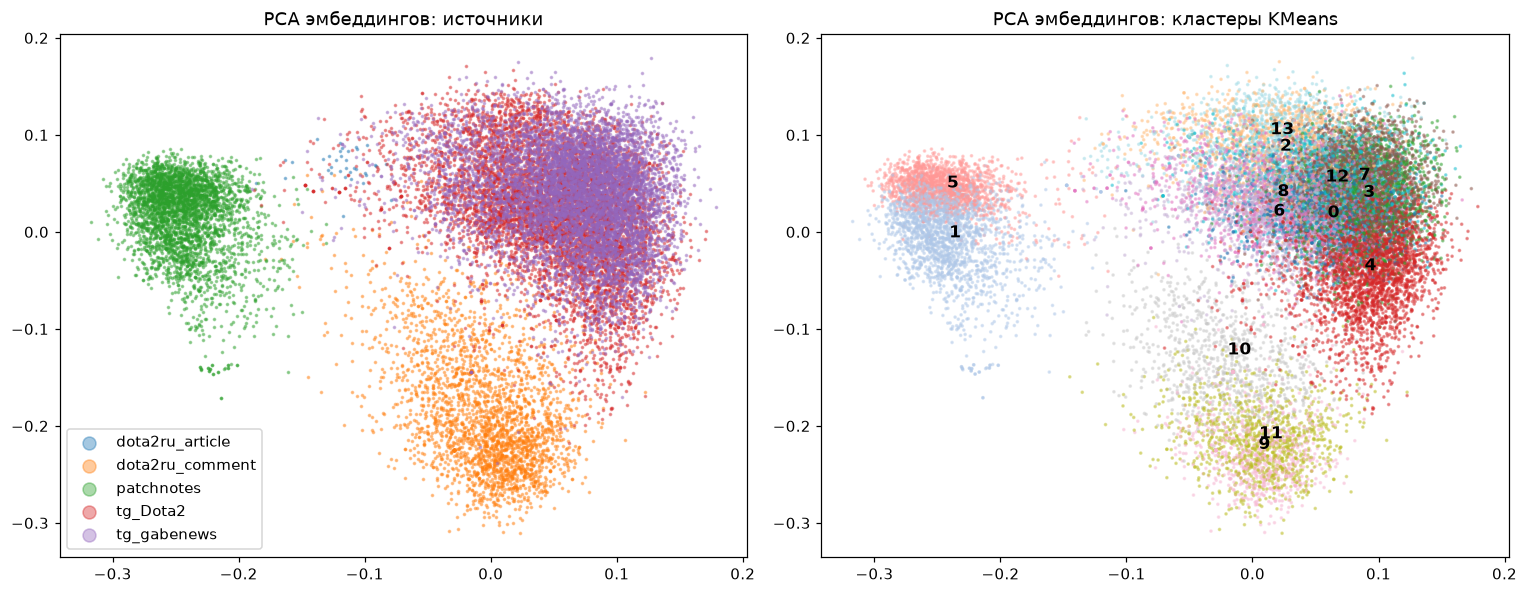

In [15]:
from sklearn.decomposition import PCA

xy = PCA(n_components=2, random_state=0).fit_transform(emb)
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
for src_name, g in df.groupby("source"):
    axes[0].scatter(xy[g.index, 0], xy[g.index, 1], s=2, alpha=0.4, label=src_name)
axes[0].legend(markerscale=6)
axes[0].set_title("PCA эмбеддингов: источники")
axes[1].scatter(xy[:, 0], xy[:, 1], c=df["cluster"], s=2, alpha=0.4, cmap="tab20")
for c in range(K):
    cx, cy = xy[df["cluster"] == c].mean(axis=0)
    axes[1].text(cx, cy, str(c), fontsize=11, weight="bold")
axes[1].set_title("PCA эмбеддингов: кластеры KMeans")
plt.tight_layout()

Примеры документов из каждого кластера:

In [16]:
for c in clusters.sort_values("docs", ascending=False).index:
    s = df[df["cluster"] == c].sample(2, random_state=0)
    print(f"--- кластер {c}: {clusters.loc[c, 'top_terms'][:80]}")
    for _, r in s.iterrows():
        print(f"  [{r['source']}] {r['visible'][:160]}")

--- кластер 4: кейкап, косплей, avice, чернуха, отчет, хайлайт, отправляй, мастерской, абузим, 
  [tg_Dota2] 🔥 Базовый Primal Beast в твоей команде Такое происходит не только в ваших пабликах, но и у Topson У Малрина научился? 🤣 @Dota2
  [tg_gabenews] Красивый камбек в тимфайте от Azure Ray ⚡️ 💎 Групповой этап Elite League | Переигровки
--- кластер 7: season, финале, расписание, счетом, пройдет, lgd, сетки, квалификации, azure, фо
  [tg_Dota2] ⚡️ Team Spirit 1-0 LGD "Драконы" без особых проблем разбираются с китайским коллективом на первой карте. Ждем легкие 2-0 или верите в камбек LGD? @Dota2
  [tg_gabenews] 🇸🇪 m1CKe пропустит игровой день на FISSURE Universe — вместо него сыграет 👑 rincyq . Завтра 🐴 Liquid сыграют против 🎮 GamerLegion с таким составом: 🗡 rincyq 🏹 M
--- кластер 1: увеличен, уменьшена, расход, увеличено, уменьшено, изменён, рецепта, восстановле
  [patchnotes] Патч 7.41d — Razor - Базовая скорость атаки увеличена со 100 до 110
  [patchnotes] Патч 7.39d — Enchantress Enc

## 6. Сводка цифр для выводов

In [17]:
summary = {
    "документов": len(df),
    "токенов видимого текста (BGE-M3)": int(df["tok_visible"].sum()),
    "токенов сырого текста": int(df["tok_raw"].sum()),
    "медиана длины, видимый": int(df["tok_visible"].median()),
    "доля < 50 токенов, %": round((df["tok_visible"] < 50).mean() * 100, 1),
    "доля > 2000 токенов, %": round((df["tok_visible"] > 2000).mean() * 100, 1),
    "мусорных единиц в сыром тексте, %": share.loc["ВСЕГО", "мусор_%"],
    "точных дубликатов, %": round(exact["exact_dup"].mean() * 100, 1),
    "документов в near-dup парах, %": round(len(near_ids) / len(df) * 100, 1),
}
pd.Series(summary).to_frame("значение")

,значение
документов,20990.0
токенов видимого текста (BGE-M3),2094307.0
токенов сырого текста,10611868.0
"медиана длины, видимый",58.0
"доля < 50 токенов, %",40.4
"доля > 2000 токенов, %",0.2
"мусорных единиц в сыром тексте, %",59.2
"точных дубликатов, %",2.2
"документов в near-dup парах, %",1.7


## 7. Выводы

**1. Типичный размер документа и разброс.** Распределение резко неоднородное, с тяжёлым хвостом:
медиана — 58 токенов видимого текста, но стандартное отклонение ~720.
* Комментарии dota2.ru — медиана 21 токен, 84% короче 50 токенов (часто это реплика из пары слов: «+1», «Почему?»).
* Посты Telegram — медиана 57–79 токенов, длинных почти нет (максимум < 1000).
* Блоки патчноутов — медиана 54, но 46% короче 50 (одна правка одного предмета) и редкие крупные блоки
  (масштабные патчи 7.36/7.38/7.41 — до 2,2 тыс. токенов на героя).
* Статьи dota2.ru — всего 36 документов (0,2% корпуса), но 16% всех токенов: медиана 4,1 тыс.,
  максимум 55 тыс. токенов; 97% длиннее 2000. Это полные пересказы патчноутов.

В итоге 40% документов короче 50 токенов, а 0,2% (все — статьи) длиннее 2000.

**2. Основной шум.** В сыром виде только 41% единиц текста — слова.
* HTML — главный шум: 38% единиц, в Telegram до 47% (`<i class="emoji">`, `<b>`, `<a href>`, `<br>`).
  Из-за разметки сырой корпус в BGE-M3-токенах в 5 раз больше видимого (10,6 млн против 2,1 млн).
* Спецсимволы — 13%, эмодзи — 3% единиц, но эмодзи есть в 99,5% постов Telegram (заголовки-рубрики).
* Ссылки — в 92–94% постов Telegram (подпись канала, промо-ссылки), сами по себе ~1% единиц.
* Числа — 16% единиц в патчноутах, но это не шум, а суть («урон увеличен с 75 до 80»):
  при чистке их удалять нельзя.
* Шаблонный текст: подписи каналов («Gabe News | Dota 2», «@Dota2»), рубрики-шаблоны
  («Еженедельный мета-отчёт»), удалённые и пустые комментарии (только картинка или цитата).
* Дубликаты: 2,2% лишних точных копий (больше всего — шаблонные посты @Dota2 и «Данный комментарий был удалён»),
  ещё 1,7% документов — почти-дубликаты, в основном отредактированные и перепощенные посты одного канала.
* Реклама ставок оказалась редкой (~1% постов) — каналы отфильтрованы по теме.

**3. Тематические кластеры.** Эмбеддинги разделяют корпус прежде всего по **стилю источника**,
а уже внутри — по теме:
* изменения способностей и героев (кластеры 1, 5 — патчноуты);
* пересказы патчей в Telegram (13) — те же факты, но другим языком;
* турниры и результаты матчей (7); составы команд, трансферы, интервью (3);
* мета и статистика: винрейты, пикрейты, «сильнейшие герои» (2, 12);
* советы, билды, механики (6); косметика, сокровищницы, мастерская (0); мемы, хайлайты, косплей (4);
* обновления в процессе: staging-сервер, утечки, Deadlock (8);
* реакции форума — жалобы на баланс, короткие эмоции, сленг (9, 10, 11).

**4. Проблемы для чанкинга и ретрива.**
* **Один размер чанка не подходит никому:** статьи надо резать, а 40% документов и так короче 50 токенов —
  фиксированный чанк в 512 токенов для них бессмыслен, а короткие комментарии без контекста статьи
  («что с ним») почти не несут информации — понадобятся метаданные (к какому патчу/статье относится).
* **Без удаления HTML** embedding-окно наполовину заполнено разметкой, а BM25 индексирует атрибуты тегов.
* **SentenceChunker** будет ошибаться на постах Telegram: предложения там разделены эмодзи, а не точками.
* **Шаблонные посты и дубликаты** будут занимать несколько мест в top-k одинаковым текстом.
* **Один факт — несколько источников:** правка есть в патчноуте, в статье, в пересказе Telegram и
  в обсуждении. В gold-наборе нужно указывать все релевантные документы, иначе Recall занизится.
* **Разные формы имён:** в патчноутах (русская локализация Valve) имена героев и предметов английские
  (Pudge, Black King Bar), в постах и комментариях — русские и сленговые (Пудж, бкб).
  BM25 на этом будет проигрывать, dense-модели должны быть мультиязычными.
* **Временная неоднозначность:** одна и та же способность меняется в нескольких патчах 7.34–7.41,
  поэтому вопросы без указания патча неоднозначны, а фильтрация по метаданным (патч, дата) должна помогать.